# Introducción a Tensorflow 2


In [40]:
import tensorflow as tf
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(tf.__version__)

2.20.0


In [41]:
tf.keras.utils.set_random_seed(42)

## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [42]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [43]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [44]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [45]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [46]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [47]:
h=model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9276 - loss: 0.2530
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9669 - loss: 0.1113
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9774 - loss: 0.0754
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9834 - loss: 0.0549
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9881 - loss: 0.0412


## Evaluación
Una vez entrenada la red neuronal, prodremos obtener las medidas de rendimiento espcificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [48]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9893 - loss: 0.0350
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9753 - loss: 0.0788


[0.07876521348953247, 0.9753000140190125]

## Prueba 1 (Cambio de épocas)

Primeramente, evaluaremos el modelo con un entrenamiento de 10 épocas y un tamaño de lote de 32 mediante el optimizadro Adam.

In [49]:
tf.keras.utils.set_random_seed(42)

model1 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

In [50]:
model1.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

A continuación, entrenaremos el modelo y mostraremos el tiempo transucrrido durante el mismo.

In [51]:
start_time = time.time()
h1=model1.fit(x_train, y_train, epochs=10, batch_size=32)
time_training1 = time.time() - start_time

print(f"Tiempo de entrenamiento: {time_training1:.2f} segundos")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9276 - loss: 0.2530
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9669 - loss: 0.1113
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9774 - loss: 0.0754
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9834 - loss: 0.0549
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9881 - loss: 0.0412
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9919 - loss: 0.0302
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9940 - loss: 0.0228
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9958 - loss: 0.0176
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9955 - loss: 0.0158
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9969 - loss: 0.0122
Tiempo de entrenamiento: 79.24 segundos


Evaluaremos y guardaremos las medidas de rendimiento (accuracy y loss) en entrenamiento y test.

In [52]:
loss_train1, acc_train1 = model1.evaluate(x_train, y_train)
loss_test1, acc_test1 = model1.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9929 - loss: 0.0210
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9762 - loss: 0.1011


Guardamos ahora los valores de las predicciones en entrenamiento y test. Comparamos entonces estos valores con los reales y calculamos el número de errores.

In [53]:
y_pred_train1 = np.argmax(model1.predict(x_train), axis = 1)
y_pred_test1 = np.argmax(model1.predict(x_test), axis = 1)

errores_train1 = np.sum(y_pred_train1 != y_train)
errores_test1 = np.sum(y_pred_test1 != y_test)

print(f"Errores en entrenamiento: {errores_train1} / {len(y_train)}")
print(f"Errores en test: {errores_test1} / {len(y_test)}")

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Errores en entrenamiento: 426 / 60000
Errores en test: 238 / 10000


Representamos las matrices de confusión tanto en el entrenamiento como en el conjunto de test mediante los errores calculados.

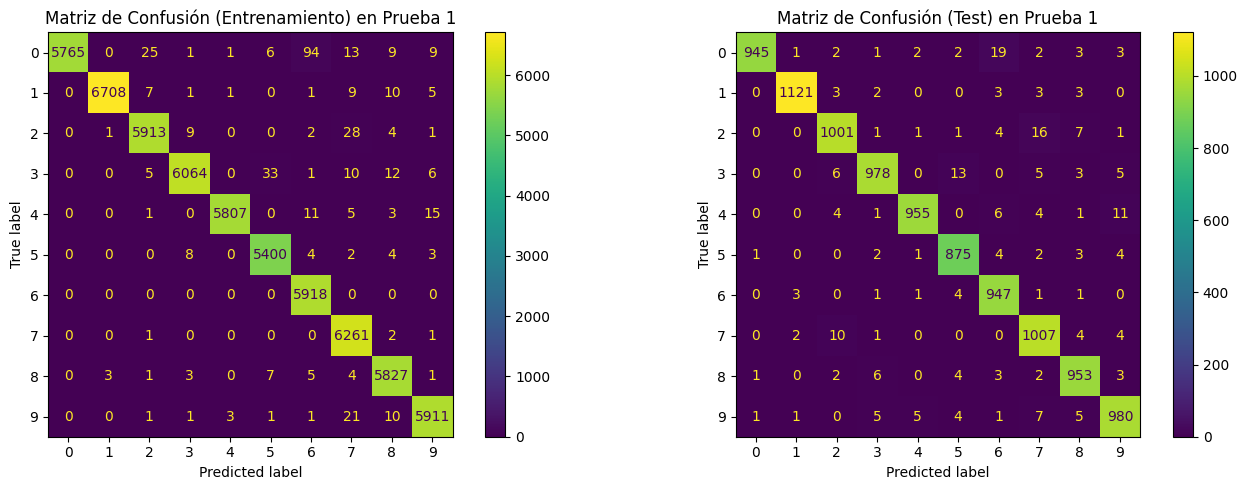

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Matriz de entrenamiento
cm_train1 = confusion_matrix(y_train, y_pred_train1)
ConfusionMatrixDisplay(cm_train1).plot(ax = axes[0])
axes[0].set_title("Matriz de Confusión (Entrenamiento) en Prueba 1")

# Matriz de test
cm_test1 = confusion_matrix(y_test, y_pred_test1)
ConfusionMatrixDisplay(cm_test1).plot(ax = axes[1])
axes[1].set_title("Matriz de Confusión (Test) en Prueba 1")

plt.tight_layout()
plt.show()

**Conclusiones**

Al aumentar las epocas de 5 a 10, comprobamos que el error en entrenamiento disminuye de 0.0350 a 0.0210. Al mismo tiempo, el numero de errores se convierte en 426 en entrenamiento, aumentando el accuracy a 99.29%. Sin embargo, se observa que aunque la precision en test tambien aumenta, la perdida lo hace tambien subiendo de 0.0788 a 0.1011 con 238 errores en test.

Con estos resultados, se verifica que al aumentar las epocas la red sigu emejorando en entrenamiento pero el incremento producido en la perdida de test muestra el principio de sobreajuste, por lo que el modelo empieza a memorizar los datos de entrenamiento y pierde capacidad de generalizaicon. Seleccionaremos esta primera prueba como modelo base

## Prueba 2 (Cambio de optimizador)

En esta prueba, realizaremos el cambio de optimizador de Adam a SGD teniendo como hiperparámetros los del modelo d ela prueba anterior, es decir, únicamente cambiaremos el optimizador con el fin de comprobar las diferencias en los resultados.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8419 - loss: 0.6319
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9079 - loss: 0.3324
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9205 - loss: 0.2849
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9286 - loss: 0.2552
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9349 - loss: 0.2328
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9402 - loss: 0.2145
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9446 - loss: 0.1991
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9488 - loss: 0.1857
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9517 - loss: 0.1741
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9549 - loss: 0.1639
Tiempo de entrenamiento: 74.83 segundos
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9566 - loss: 0.1566
3

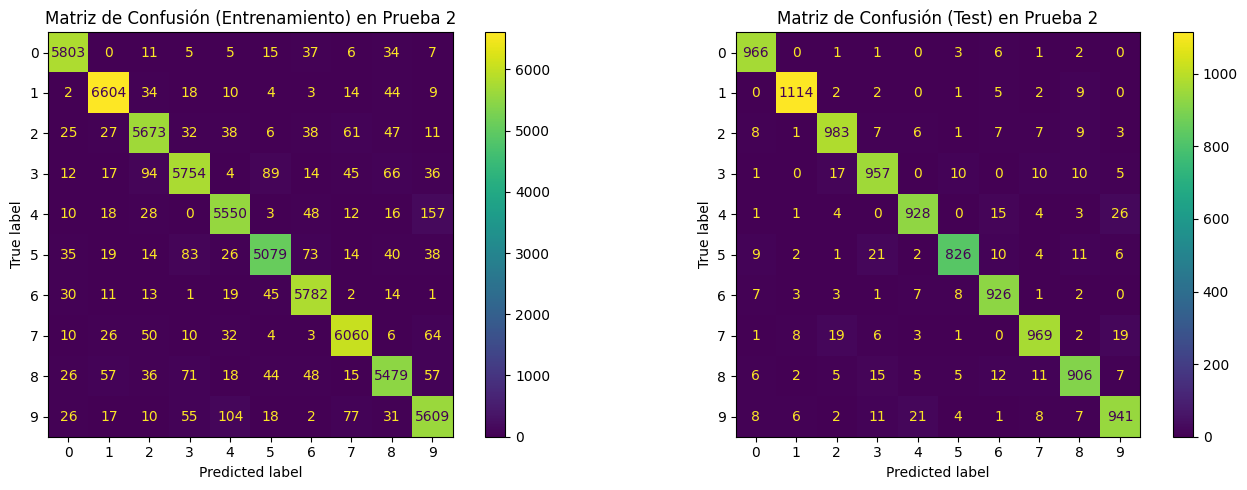

In [55]:
# Semilla
tf.keras.utils.set_random_seed(42)

# Modelo
model2 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

# Compilación
model2.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamiento y tiempo
start_time = time.time()
h2=model2.fit(x_train, y_train, epochs=10, batch_size=32)
time_training2 = time.time() - start_time

print(f"Tiempo de entrenamiento: {time_training2:.2f} segundos")

# Evaluación numérica
loss_train2, acc_train2 = model2.evaluate(x_train, y_train)
loss_test2, acc_test2 = model2.evaluate(x_test, y_test)

# Predicciones y cálculo de errores
y_pred_train2 = np.argmax(model2.predict(x_train), axis = 1)
y_pred_test2 = np.argmax(model2.predict(x_test), axis = 1)

errores_train2 = np.sum(y_pred_train2 != y_train)
errores_test2 = np.sum(y_pred_test2 != y_test)

print(f"Errores en entrenamiento: {errores_train2} / {len(y_train)}")
print(f"Errores en test: {errores_test2} / {len(y_test)}")

# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Matriz de entrenamiento
cm_train2 = confusion_matrix(y_train, y_pred_train2)
ConfusionMatrixDisplay(cm_train2).plot(ax = axes[0])
axes[0].set_title("Matriz de Confusión (Entrenamiento) en Prueba 2")

# Matriz de test
cm_test2 = confusion_matrix(y_test, y_pred_test2)
ConfusionMatrixDisplay(cm_test2).plot(ax = axes[1])
axes[1].set_title("Matriz de Confusión (Test) en Prueba 2")

plt.tight_layout()
plt.show()

**Conclusiones**

En este caso hemos mantenido 10 epocas y un tamaño de lote de 32, sin embargo, al cambiar el optimizador de Adam a SGD observamos un cambio significativo en el rendimiento.

Por una parte, el tiempo de entrenamiento es similar al de la Prueba 1. Asimismo, la exactitud en entrenamiento disminuye de 99.29% a 95.66%, es decir de 426 a 2607 errores, y la exactitud en test pasa de 97.62% a 95.16%, es decir de 238 a 484 errores.

No obstante, el error de entrenamiento es de 0.1566 y el de test 0.1617, siendo una diferencia apenas significativa. Luego SGD no presenta sobreajuste pero su congergencia es mucho mas lenta y requeriria mas epocas para alcanzar la precision de Adam.

## Prueba 3 (Cambio de Batch Size)

En esta prueba estudiaremos el cambio al aumentar el tamaño del lote de 32 a 256, además mantenemos Adam de optimizador y 10 épocas. Veamos cómo afectan bloques de datos más grandes al tiempo y la precisión.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8817 - loss: 0.4361
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9446 - loss: 0.1967
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9586 - loss: 0.1450
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9677 - loss: 0.1149
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9733 - loss: 0.0949
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9777 - loss: 0.0803
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9808 - loss: 0.0689
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9836 - loss: 0.0598
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9859 - loss: 0.0522
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9880 - loss: 0.0459
Tiempo de entrenamiento: 18.84 segundos
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9901 - loss: 0.0397
313/313 ━━━━━━━━━━━━

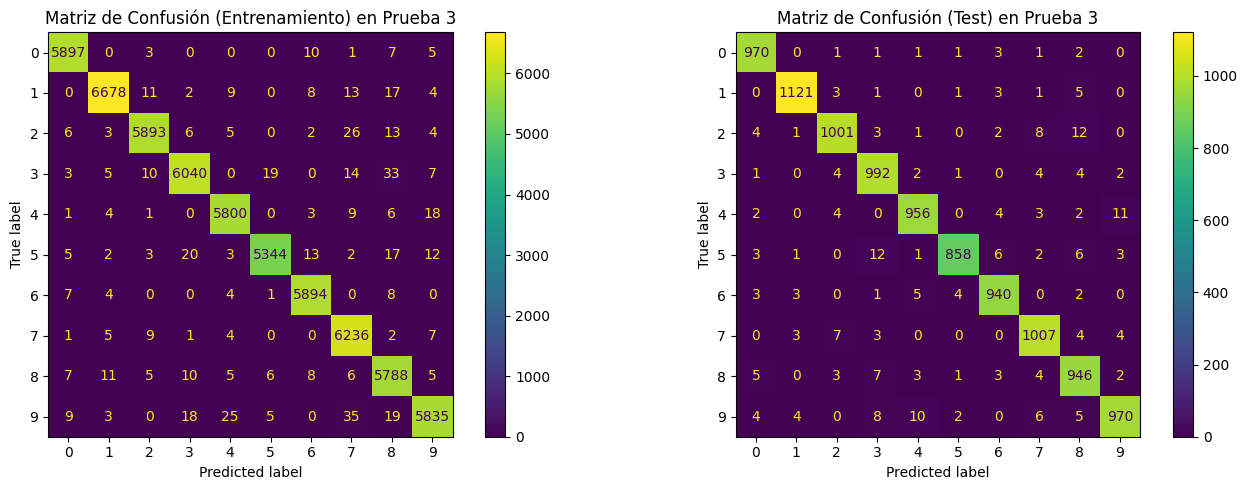

In [56]:
# Semilla
tf.keras.utils.set_random_seed(42)

# Modelo
model3 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

# Compilación
model3.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamiento y tiempo
start_time = time.time()
h3=model3.fit(x_train, y_train, epochs=10, batch_size=256)
time_training3 = time.time() - start_time

print(f"Tiempo de entrenamiento: {time_training3:.2f} segundos")

# Evaluación numérica
loss_train3, acc_train3 = model3.evaluate(x_train, y_train)
loss_test3, acc_test3 = model3.evaluate(x_test, y_test)

# Predicciones y cálculo de errores
y_pred_train3 = np.argmax(model3.predict(x_train), axis = 1)
y_pred_test3 = np.argmax(model3.predict(x_test), axis = 1)

errores_train3 = np.sum(y_pred_train3 != y_train)
errores_test3 = np.sum(y_pred_test3 != y_test)

print(f"Errores en entrenamiento: {errores_train3} / {len(y_train)}")
print(f"Errores en test: {errores_test3} / {len(y_test)}")

# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Matriz de entrenamiento
cm_train3 = confusion_matrix(y_train, y_pred_train3)
ConfusionMatrixDisplay(cm_train3).plot(ax = axes[0])
axes[0].set_title("Matriz de Confusión (Entrenamiento) en Prueba 3")

# Matriz de test
cm_test3 = confusion_matrix(y_test, y_pred_test3)
ConfusionMatrixDisplay(cm_test3).plot(ax = axes[1])
axes[1].set_title("Matriz de Confusión (Test) en Prueba 3")

plt.tight_layout()
plt.show()

**Conclusiones**

Al incrementar el tamaño del ote de 32 a 256 manteniendo el resto de hiperparámetros observamos primeramente la disminución drástica del tiempo de entrenamiento, pasando de alrededor de 79 segundos a 18.84 segundos. Esto ocurre ya que al procesar bloques de datos más grandes en paralelo, se reduce el número total de actualizaciones de pesos por época.

Por otro lado, la pérdida en test disminuye de 0.1011 en la Prueba 1 a 0.0761 y la precisión se mantiene casi idéntica siendo de 97.61% y 239 errores. Por tanto, los lotes más grandes ayudan a estabilizar el gradiente y evitan el osbreajuste.

## Prueba 4 (Búsqueda del mejor modelo)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9182 - loss: 0.2934
Epoch 2/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9622 - loss: 0.1301
Epoch 3/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9734 - loss: 0.0904
Epoch 4/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9803 - loss: 0.0686
Epoch 5/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9847 - loss: 0.0535
Epoch 6/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9884 - loss: 0.0423
Epoch 7/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9917 - loss: 0.0333
Epoch 8/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9941 - loss: 0.0262
Epoch 9/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9954 - loss: 0.0206
Epoch 10/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9969 - loss: 0.0158
Epoch 11/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9976 - loss: 0.0129
Epoch 12/12
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/ste

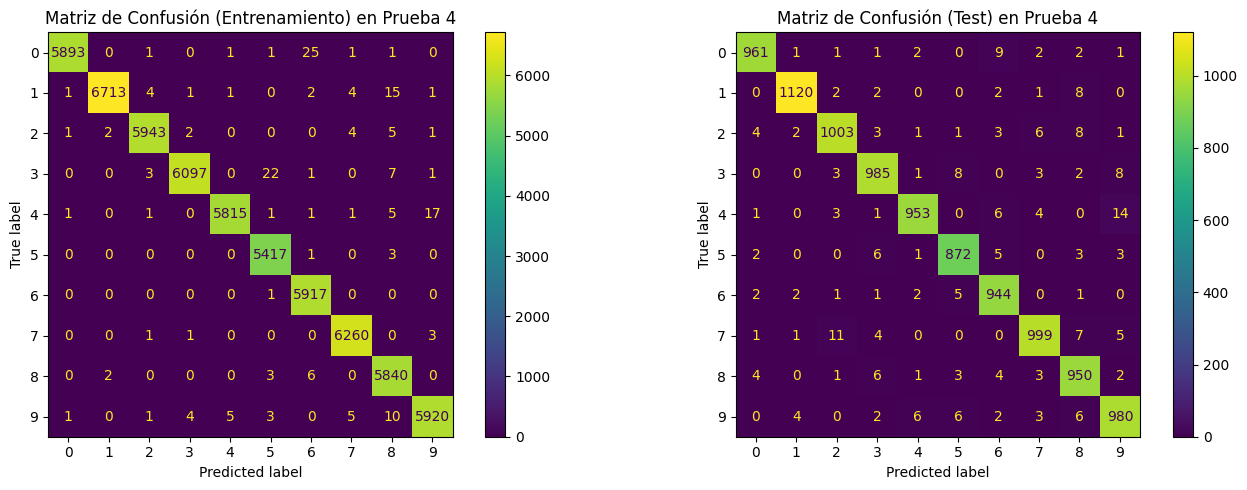

In [57]:
# Semilla
tf.keras.utils.set_random_seed(42)

# Modelo
model4 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

# Compilación
model4.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamiento y tiempo
start_time = time.time()
h4=model4.fit(x_train, y_train, epochs=12, batch_size=64)
time_training4 = time.time() - start_time

print(f"Tiempo de entrenamiento: {time_training4:.2f} segundos")

# Evaluación numérica
loss_train4, acc_train4 = model4.evaluate(x_train, y_train)
loss_test4, acc_test4 = model4.evaluate(x_test, y_test)

# Predicciones y cálculo de errores
y_pred_train4 = np.argmax(model4.predict(x_train), axis = 1)
y_pred_test4 = np.argmax(model4.predict(x_test), axis = 1)

errores_train4 = np.sum(y_pred_train4 != y_train)
errores_test4 = np.sum(y_pred_test4 != y_test)

print(f"Errores en entrenamiento: {errores_train4} / {len(y_train)}")
print(f"Errores en test: {errores_test4} / {len(y_test)}")

# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Matriz de entrenamiento
cm_train4 = confusion_matrix(y_train, y_pred_train4)
ConfusionMatrixDisplay(cm_train4).plot(ax = axes[0])
axes[0].set_title("Matriz de Confusión (Entrenamiento) en Prueba 4")

# Matriz de test
cm_test4 = confusion_matrix(y_test, y_pred_test4)
ConfusionMatrixDisplay(cm_test4).plot(ax = axes[1])
axes[1].set_title("Matriz de Confusión (Test) en Prueba 4")

plt.tight_layout()
plt.show()

**Conclusiones**

Finalmente, se ajustaron los hiperparámetros a un equilibrio intermedio con un tamaño de lote de 64 y 12 épocas con Adam.

Con los resultados obtenidos observamos que se logra el menor número de fallos en el conjunto de test (233 errores con un 97.67% de accuracy) y en entrenamiento con 185 errores.

Por otro lado, el tiempo de ejecución es menor que en la Prueba 1 siendo de 56.62 segundos. Aunque el tiempo es moderado, no existe sobreajuste, demostrando que un batch size intermedio de 64 permite un equilibrio entre velocidad por época y capacidad de generalización.

## Estudio Comparativo de las Pruebas

In [58]:
# Creamos una tabla comparativa de las 4 pruebas
tabla_comparativa = pd.DataFrame({
    'Experimento': [
        'Prueba 1 (Adam, b=32, e=10)',
        'Prueba 2 (SGD, b=32, e=10)',
        'Prueba 3 (Adam, b=256, e=10)',
        'Prueba 4 (Adam, b=64, e=12)'
    ],
    'Tiempo (s)': [time_training1, time_training2, time_training3, time_training4],
    'Acc Train': [acc_train1, acc_train2, acc_train3, acc_train4],
    'Acc Test': [acc_test1, acc_test2, acc_test3, acc_test4],
    'Loss Test': [loss_test1, loss_test2, loss_test3, loss_test4],
    'Errores Test': [errores_test1, errores_test2, errores_test3, errores_test4]
})

# Mostramos la tabla
display(tabla_comparativa)

,Experimento,Tiempo (s),Acc Train,Acc Test,Loss Test,Errores Test
0,"Prueba 1 (Adam, b=32, e=10)",79.236445,0.992900,0.9762,0.101119,238
1,"Prueba 2 (SGD, b=32, e=10)",74.832808,0.956550,0.9516,0.161733,484
2,"Prueba 3 (Adam, b=256, e=10)",18.836131,0.990083,0.9761,0.076066,239
3,"Prueba 4 (Adam, b=64, e=12)",56.624796,0.996917,0.9767,0.089527,233


Generamos a continuación gráficas para los tiempos, accuracy y los errores de las pruebas que hemos realizado.

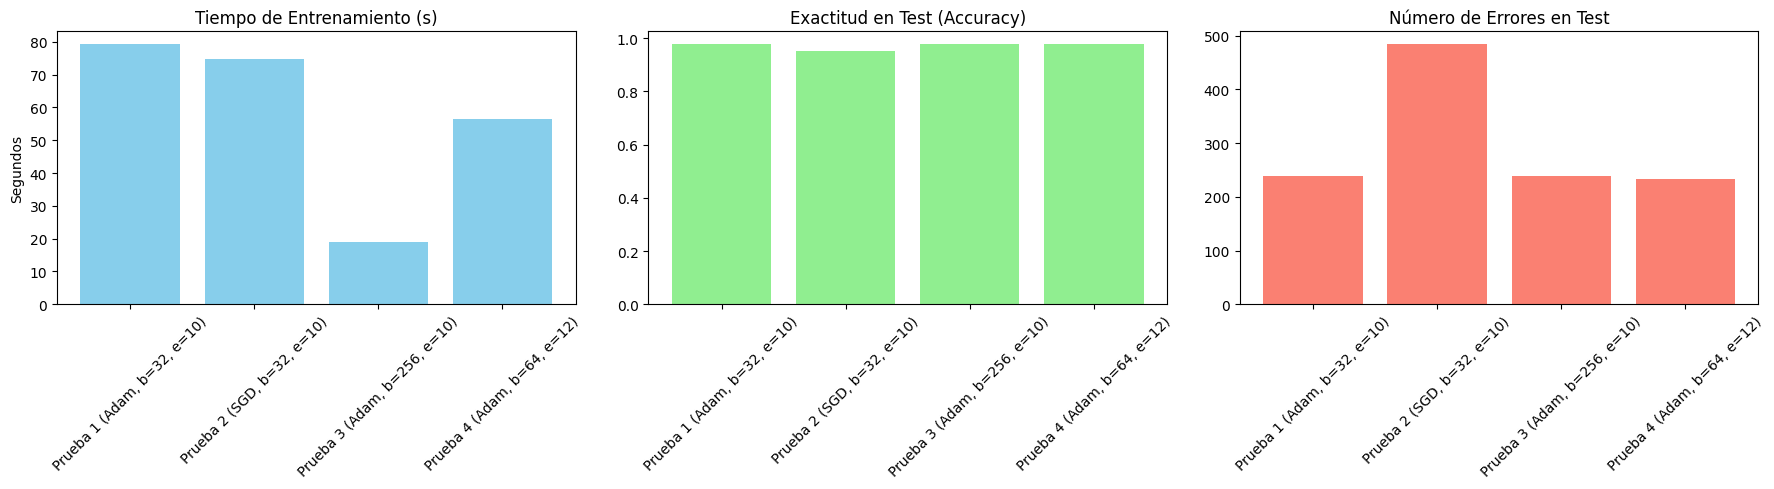

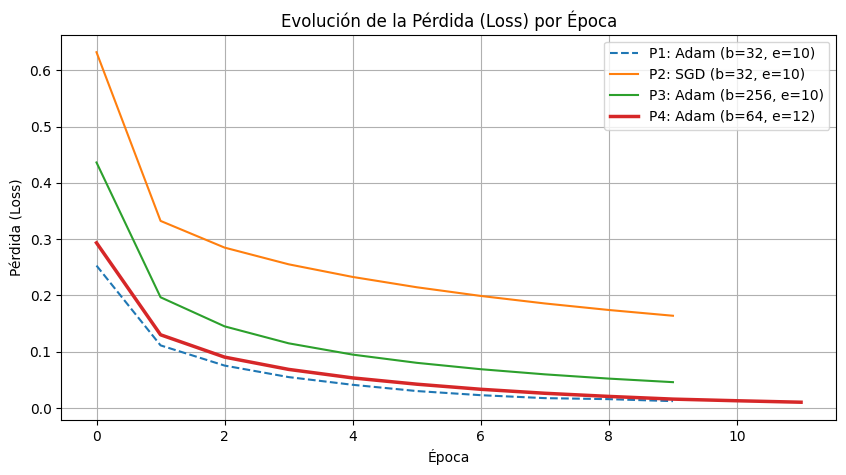

In [59]:
# Gráficas de barras comparativas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica de los tiempos
axes[0].bar(tabla_comparativa['Experimento'], tabla_comparativa['Tiempo (s)'], color='skyblue')
axes[0].set_title('Tiempo de Entrenamiento (s)')
axes[0].set_ylabel('Segundos')
axes[0].tick_params(axis='x', rotation=45)

# Gráfica de accuracy en test
axes[1].bar(tabla_comparativa['Experimento'], tabla_comparativa['Acc Test'], color='lightgreen')
axes[1].set_title('Exactitud en Test (Accuracy)')
axes[1].tick_params(axis='x', rotation=45)

# Gráfica de los errores en test
axes[2].bar(tabla_comparativa['Experimento'], tabla_comparativa['Errores Test'], color='salmon')
axes[2].set_title('Número de Errores en Test')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Curva de la evolución del loss por época
plt.figure(figsize=(10, 5))
plt.plot(h1.history['loss'], label='P1: Adam (b=32, e=10)', linestyle='--')
plt.plot(h2.history['loss'], label='P2: SGD (b=32, e=10)')
plt.plot(h3.history['loss'], label='P3: Adam (b=256, e=10)')
plt.plot(h4.history['loss'], label='P4: Adam (b=64, e=12)', linewidth=2.5)

plt.title('Evolución de la Pérdida (Loss) por Época')
plt.xlabel('Época')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Guardamos ahora el mejor modelo entrenado en disco.

In [60]:
model4.save('mejor_modelo_mnist.keras')

## Conclusión Final

Tras la ejecución de las diferentes pruebas, obtenemos un análisis de los distintos hiperparámetros.

Primeramente, en cuanto a optimizadores se comprueba que Adam es superior en velocidad de convergencias en este tipo de arquitectura, en cambio el caso de SGD muestra que se queda atascado cerca del 95.16% de precisión frente al 97.6% que alcanza Adam en test.

Por otra parte, aumentar el tamaño del lote a 256 reduce de forma significativa el tiempo de ejecución además de reducir la pérdida en test.

Finalmente, hemos seleccioando la Prueba 4 con Adam como optimizador, un tamaño de lote de 64 y 12 épocas por ser la configuración que minimiza el error en el conjunto de prueba a 233 errores totales optimizando a la vez el tiempo total respecto a la configuración base. Por ello además, este modelo se ha esportado a disco.